# 05 — GARCH(1,1) + Filtered Historical Simulation

**Tail Risk Adequacy — Stress-Testing Risk Metrics Across Distributional Assumptions and Market Regimes**
High_Magus_of_Risk

---

## Purpose

This is the **Phase 2 entry point**. Phase 1 produced four parametric rolling-window engines (Gaussian and Student-t at $\nu \in \{4, 6, 10\}$) and showed in notebook 04 that **every** engine rejects both Kupiec coverage and Christoffersen independence at $p < 0.0001$. The §4.6 diagnostic in notebook 04 attributed those rejections to two distinct failure modes:

1. **Marginal mis-calibration** — Gaussian under-estimates fat tails; Student-t partially corrects but does not eliminate.
2. **Dynamic mis-calibration** — even when the marginal is well-chosen, a rolling 4-year $\hat{\sigma}_t$ cannot react to volatility spikes within days, so exceptions cluster in stress regimes.

The Phase 2 engine in this notebook targets failure mode (2) directly: it replaces the rolling $\hat{\sigma}_t$ with a **GARCH(1,1)-implied conditional volatility** that adapts to volatility regimes within days, and uses **Filtered Historical Simulation** (FHS) to obtain the tail quantile non-parametrically from the standardised residuals.

The result will be a fifth engine, slotted into the same backtest infrastructure built in notebook 04 — same scorecard format, same stress windows, same Kupiec + Christoffersen battery.


---
## 1  Environment Setup

In [1]:
import warnings
warnings.filterwarnings('ignore')

import os, sys, json, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

sys.path.insert(0, os.path.abspath('src'))
from risk import (
    backtest_var_es,
    mcneil_frey_es_test, acerbi_szekely_z2, backtest_es,
)
from garch_fhs import rolling_garch_fhs, fit_garch_window

plt.rcParams['figure.dpi'] = 110
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3


---
## 2  Methodology

### 2.1  Two diagnostic gaps that GARCH-FHS closes

Recall the dual-test framework derived in notebook 04, §4. A VaR engine has two distinct calibration questions, each with its own test:

| Failure mode | Detected by | What Phase 1 said |
|---|---|---|
| Marginal mis-calibration | Kupiec POF ($\mathrm{LR}_{\mathrm{uc}}$) | $t$-engines reduce magnitude but still reject |
| Dynamic mis-calibration | Christoffersen ind. ($\mathrm{LR}_{\mathrm{ind}}$) | All four engines reject equally — the rolling $\hat{\sigma}_t$ is too sluggish |

Phase 2 attacks both gaps simultaneously: (a) GARCH(1,1) supplies a **dynamic** $\sigma_t$ that adapts to volatility regimes, addressing failure (2); (b) FHS resamples standardised residuals **non-parametrically**, so the empirical tail shape is whatever the data say, addressing failure (1).

### 2.2  GARCH(1,1) specification

The model assumes a zero-mean innovation process

$$
r_t \;=\; \sigma_t \cdot z_t, \qquad z_t \stackrel{\text{iid}}{\sim} (0, 1)
$$

with the conditional-variance recursion

$$
\boxed{\;
\sigma_t^2 \;=\; \omega + \alpha\,r_{t-1}^2 + \beta\,\sigma_{t-1}^2,
\quad \omega > 0,\; \alpha,\beta \ge 0,\; \alpha + \beta < 1.
\;}
$$

Three parameters: $\omega$ (long-run variance baseline), $\alpha$ (ARCH; sensitivity to recent shocks), $\beta$ (GARCH; persistence of past variance). The constraint $\alpha + \beta < 1$ ensures stationarity; in practice for daily equity returns we expect $\alpha + \beta \approx 0.97$–$0.99$ — high persistence but still mean-reverting in the long run.

**Why this specification, not GJR or EGARCH?** GARCH(1,1) is the textbook benchmark and the most defensible single Phase 2 addition. Asymmetric extensions (GJR-GARCH, EGARCH) capture the leverage effect — negative shocks raise volatility more than positive shocks of equal magnitude — but they add parameters and methodological complexity. We reserve them as Phase 3 robustness checks; for the consulting report, GARCH(1,1) is the right level of sophistication.

### 2.3  Filtered Historical Simulation

After fitting GARCH(1,1) on a window, define the **standardised residual**

$$
z_t \;=\; \frac{r_t}{\sigma_t}
$$

where $\sigma_t$ is the conditional volatility implied by the fit. By construction $\{z_t\}$ are approximately iid with unit variance. Their **empirical distribution** $\widehat{F}_z$ is the FHS "pool" of innovations.

For a 1-day-ahead VaR/ES forecast at confidence $\alpha$:

$$
\boxed{\;
\mathrm{VaR}_{\alpha,t+1}^{\text{FHS}}
\;=\; -\sigma_{t+1} \cdot \widehat{F}_z^{\,-1}(1-\alpha),
\qquad
\mathrm{ES}_{\alpha,t+1}^{\text{FHS}}
\;=\; -\sigma_{t+1} \cdot \mathbb{E}\!\left[z \;\middle|\; z \le \widehat{F}_z^{\,-1}(1-\alpha)\right].
\;}
$$

The minus sign converts the lower-tail quantile of returns into a positive loss. Crucially, the *distributional shape* enters through $\widehat{F}_z$ — no Gaussian, no Student-t assumption.

**Why FHS rather than parametric GARCH-t?** Both are defensible. FHS has three advantages for *this* project:

1. **Empirical, not assumed.** The standardised residuals carry whatever fat-tail / skew structure the data show, without forcing a parametric family.
2. **Compatible with the project's research question.** The whole point of the dual-test framework is to separate distribution from dynamics. FHS isolates the dynamics question (does GARCH-filtering help?) cleanly, leaving the distributional question free of additional parametric assumptions.
3. **Practitioner standard.** Recommended by Barone-Adesi, Giannopoulos & Vosper (1999) and used routinely in industry risk systems for exactly this scenario.

### 2.4  Rolling pipeline

We use the same 750-day rolling estimation window as the Phase 1 engines, ensuring an apples-to-apples comparison. To avoid ~6,800 daily GARCH refits (which would take ~30 min and add little statistical benefit), we follow the practitioner convention of **monthly refits** (every 20 business days). Between refits:

- The GARCH parameters $(\omega, \alpha, \beta)$ stay fixed.
- The conditional variance is updated daily using the GARCH recursion: $\sigma_{t+1}^2 = \omega + \alpha r_t^2 + \beta \sigma_t^2$.
- The residual pool $\widehat{F}_z$ stays fixed at the most recent fit.

This is the standard industry pipeline; the alternative (daily refit) is implementable via `refit_freq=1` and produces near-identical results at much higher computational cost.

### 2.5  Engine module

The closed-form math, the rolling pipeline, and the residual-pool resampling all live in `src/garch_fhs.py`. The module is unit-tested in `tests/test_garch_fhs.py` (9 tests), including a regime-shift test that verifies the engine's $\sigma$ forecast adapts when input volatility jumps from 0.5% to 3% (it rose from 0.47% to 3.25% in the test).

### 2.6  Reference

- **Barone-Adesi, G., Giannopoulos, K., & Vosper, L.** (1999). "VaR Without Correlations for Non-Linear Portfolios." *Journal of Futures Markets*, 19(5), 583–602.
- **Bollerslev, T.** (1986). "Generalized Autoregressive Conditional Heteroskedasticity." *Journal of Econometrics*, 31(3), 307–327.
- **Engle, R.F.** (1982). "Autoregressive Conditional Heteroscedasticity with Estimates of the Variance of United Kingdom Inflation." *Econometrica*, 50(4), 987–1007.


---
## 3  Configuration

In [2]:
CONFIG = {
    'alpha'      : 0.99,
    'window'     : 1000,
    'refit_freq' : 20,
    'portfolios' : ['Port_FO'],
    'portfolio_labels': {
        'Port_FO': 'Family-Office Portfolio (40/25/15/10/10)',
    },
}
print(f'Confidence: {CONFIG["alpha"]:.0%}')
print(f'Window:     {CONFIG["window"]} business days (~4y)')
print(f'Refit:      every {CONFIG["refit_freq"]} days (monthly)')

Confidence: 99%
Window:     1000 business days (~4y)
Refit:      every 20 days (monthly)


---
## 4  Load Returns and Phase 1 Forecasts

We need both the raw returns (for the GARCH fit) and the Phase 1 forecast CSVs (for the head-to-head comparison at the end).

In [3]:
returns = pd.read_csv('data/returns.csv', index_col=0, parse_dates=True)
phase1_by_port = {p: pd.read_csv(f'data/forecasts/{p}.csv', index_col=0, parse_dates=True)
                  for p in CONFIG['portfolios']}
with open('data/stress_windows.json') as f:
    STRESS_WINDOWS = json.load(f)
print(f'Returns: {returns.shape}')
print(f'Stress windows: {list(STRESS_WINDOWS.keys())}')

Returns: (7485, 8)
Stress windows: ['DotCom_2000_2003', 'GFC', 'COVID', 'Rate_Hikes_2022']


---
## 5  Single-Window Diagnostic — Recent 5 Years

Before running the rolling pipeline, we fit a GARCH(1,1) on the most recent 3 years of FO returns and inspect the result. Three pieces of evidence to extract:

1. **Estimated parameters** $(\omega, \alpha, \beta)$ — the persistence $\alpha + \beta$ should be close to 1, confirming the volatility-clustering finding from notebook 02.
2. **Conditional-volatility time series** — visually, $\hat{\sigma}_t$ should track the major realised-vol episodes (2020, late 2022, 2023).
3. **Standardised-residual distribution** — should have mean ≈ 0, std ≈ 1, and a QQ-shape that visually rejects normality (heavy left tail). This is the FHS pool we will use for VaR/ES quantile computation.

In [4]:
diag_data = returns['Port_FO'].iloc[-CONFIG['window']:]
res_diag = fit_garch_window(diag_data)
print(res_diag.summary())

                       Zero Mean - GARCH Model Results                        
Dep. Variable:                Port_FO   R-squared:                       0.000
Mean Model:                 Zero Mean   Adj. R-squared:                  0.001
Vol Model:                      GARCH   Log-Likelihood:               -1009.86
Distribution:                  Normal   AIC:                           2025.73
Method:            Maximum Likelihood   BIC:                           2040.45
                                        No. Observations:                 1000
Date:                Thu, Jun 04 2026   Df Residuals:                     1000
Time:                        20:28:59   Df Model:                            0
                              Volatility Model                              
                 coef    std err          t      P>|t|      95.0% Conf. Int.
----------------------------------------------------------------------------
omega          0.0106  5.212e-03      2.025  4.282e-02 [3.

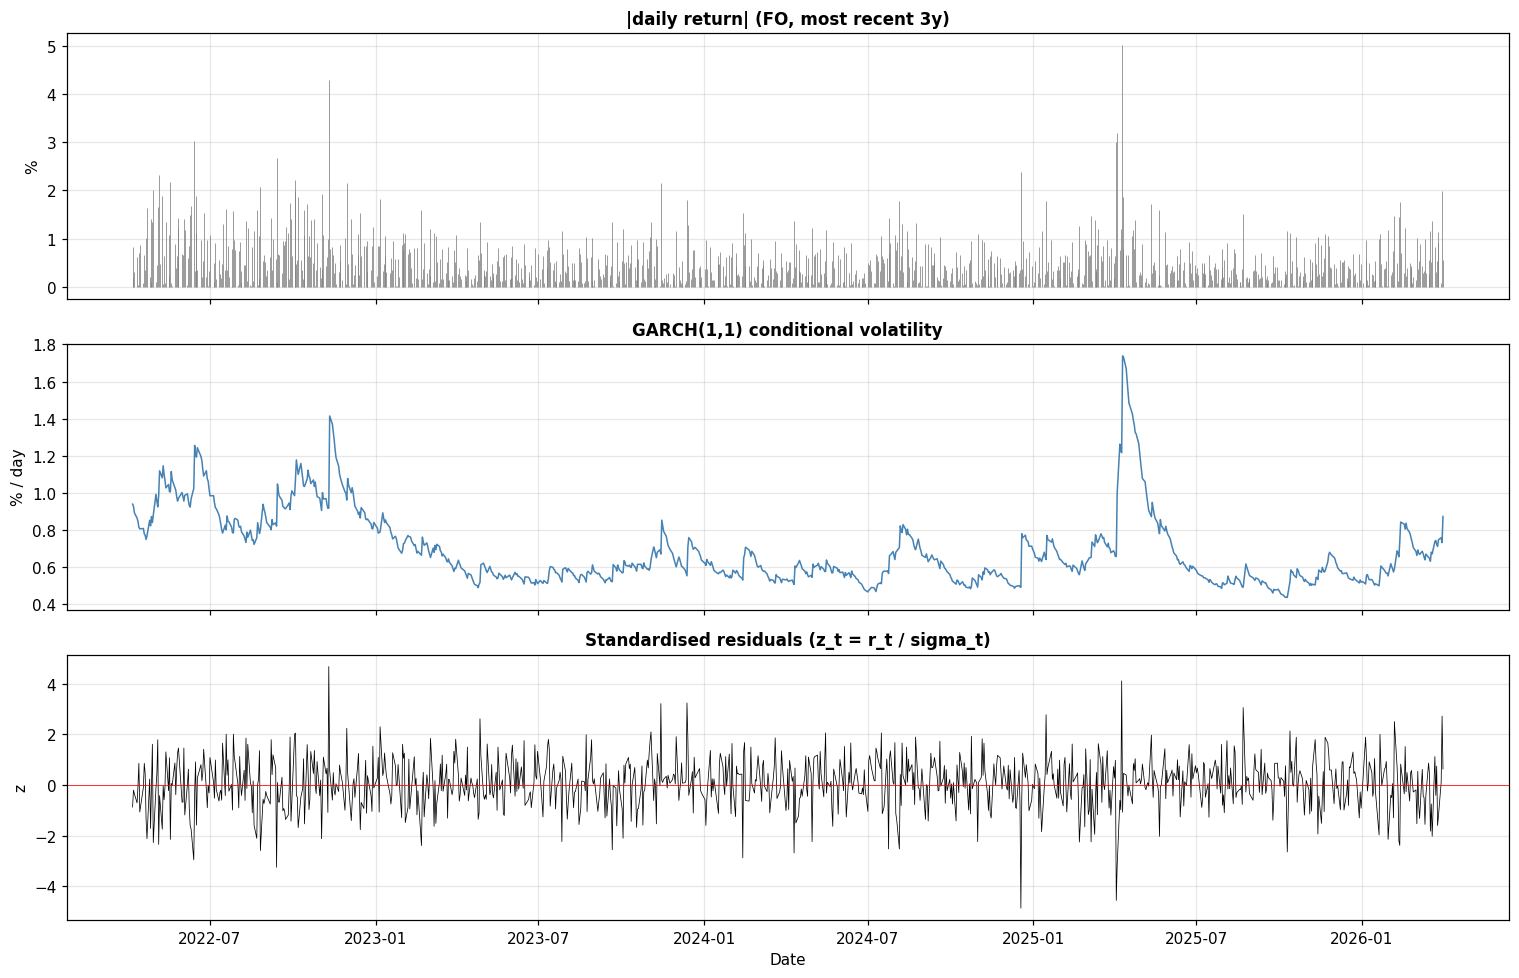


z_t summary: mean=0.0615, std=0.9987, skew=-0.198, exc.kurt=1.764


In [5]:
# Three diagnostic panels: realised |r|, conditional sigma, std residuals
fig, axes = plt.subplots(3, 1, figsize=(14, 9), sharex=True)
realised_abs_pct = diag_data.abs() * 100
cond_sigma_pct = res_diag.conditional_volatility   # already in %
std_resid = res_diag.std_resid

axes[0].vlines(realised_abs_pct.index, 0, realised_abs_pct.values, color='grey', lw=0.5)
axes[0].set_title('|daily return| (FO, most recent 3y)', fontsize=11, fontweight='bold')
axes[0].set_ylabel('%')

axes[1].plot(cond_sigma_pct.index, cond_sigma_pct.values, color='steelblue', lw=1.0)
axes[1].set_title('GARCH(1,1) conditional volatility', fontsize=11, fontweight='bold')
axes[1].set_ylabel('% / day')

axes[2].plot(std_resid.index, std_resid.values, color='black', lw=0.5)
axes[2].axhline(0, color='red', lw=0.5)
axes[2].set_title('Standardised residuals (z_t = r_t / sigma_t)', fontsize=11, fontweight='bold')
axes[2].set_ylabel('z')
axes[2].set_xlabel('Date')

plt.tight_layout()
plt.show()

print(f'\nz_t summary: mean={std_resid.mean():.4f}, std={std_resid.std():.4f}, '
      f'skew={std_resid.skew():.3f}, exc.kurt={std_resid.kurtosis():.3f}')

---
## 6  Run the Rolling GARCH-FHS Pipeline

For each portfolio, run the rolling 1-day-ahead pipeline described in §2.4. The expected runtime is ~7-10 seconds per portfolio at the 20-day refit cadence — fast enough to iterate on.

In [6]:
garch_fhs_forecasts = {}

for port in CONFIG['portfolios']:
    t0 = time.time()
    fc = rolling_garch_fhs(
        returns[port].dropna(),
        window=CONFIG['window'],
        alpha=CONFIG['alpha'],
        refit_freq=CONFIG['refit_freq'],
        verbose=False,
    )
    elapsed = time.time() - t0
    garch_fhs_forecasts[port] = fc
    print(f'  {port:<20s} {len(fc):,} forecasts in {elapsed:.1f}s '
          f'(mean VaR {fc["VaR"].mean()*100:.3f}%, mean sigma {fc["sigma"].mean()*100:.3f}%)')

  Port_FO              6,485 forecasts in 3.5s (mean VaR 1.594%, mean sigma 0.622%)


---
## 7  Backtest the GARCH-FHS Engine

Run the Kupiec + Christoffersen battery (derived in notebook 04 §4) on the new engine, both overall and on each stress window. The reading frame from notebook 04:

- $\mathrm{LR}_{\mathrm{uc}}$ measures coverage failure — should drop substantially vs Phase 1 because FHS captures fat tails empirically.
- $\mathrm{LR}_{\mathrm{ind}}$ measures clustering — should drop by an *order of magnitude* vs Phase 1 because GARCH-filtered $\sigma$ adapts to volatility regimes.
- $\mathrm{LR}_{\mathrm{cc}} = \mathrm{LR}_{\mathrm{uc}} + \mathrm{LR}_{\mathrm{ind}}$.

In [7]:
rows = []
for port in CONFIG['portfolios']:
    fc = garch_fhs_forecasts[port][['VaR', 'ES']]
    result = backtest_var_es(returns[port], fc, alpha=CONFIG['alpha'])
    k = result['kupiec']
    c = result['christoffersen']
    rows.append({
        'Portfolio'     : port,
        'Engine'        : 'GARCH-FHS',
        'N obs'         : result['n_obs'],
        'N exc'         : result['n_exceptions'],
        'Exc rate'      : result['exception_rate'],
        'Target'        : result['expected_exception_rate'],
        'Mean L|exc'    : result['mean_loss_given_exception'],
        'Mean (L-ES)|exc': result['mean_es_severity'],
        'LR_uc (Kupiec)': k['lr_uc'],
        'p_uc'          : k['p_value'],
        'LR_ind (Christ)' : c['lr_ind'],
        'p_ind'         : c['p_ind'],
        'LR_cc'         : c['lr_cc'],
        'p_cc'          : c['p_cc'],
    })

phase2_overall = pd.DataFrame(rows).set_index(['Portfolio', 'Engine'])

def _fmt(df):
    out = df.copy()
    for c in ['Exc rate', 'Target', 'Mean L|exc', 'Mean (L-ES)|exc']:
        if c in out.columns:
            out[c] = out[c].map(lambda x: f'{x*100:+.3f}%' if pd.notna(x) else '—')
    for c in ['LR_uc (Kupiec)', 'LR_ind (Christ)', 'LR_cc']:
        if c in out.columns:
            out[c] = out[c].map(lambda x: f'{x:.2f}' if pd.notna(x) else '—')
    for c in ['p_uc', 'p_ind', 'p_cc']:
        if c in out.columns:
            out[c] = out[c].map(lambda x: f'{x:.4f}' if pd.notna(x) else '—')
    return out

display(_fmt(phase2_overall))

,,N obs,N exc,Exc rate,Target,Mean L|exc,Mean (L-ES)|exc,LR_uc (Kupiec),p_uc,LR_ind (Christ),p_ind,LR_cc,p_cc
Portfolio,Engine,,,,,,,,,,,,
Port_FO,GARCH-FHS,6485,80,+1.234%,+1.000%,+1.822%,-0.038%,3.33,0.0681,2.75,0.0974,6.08,0.0479


---
## 5  ES Backtest — GARCH-FHS Overall

Same battery as in NB04 §8, now applied to the Phase 2 GARCH-FHS engine. Two questions:

- Does GARCH-FHS' adaptive conditional volatility translate into a passing McNeil-Frey p-value (the test that t_4 only marginally failed in NB04)?
- Does the Z2 statistic collapse toward zero — the "ES correctly calibrated on aggregate" result the project hypothesised in §4.9?

A clear improvement on McNeil-Frey relative to Phase 1 t_4 (and especially Gaussian) would be the cleanest single signal that "fixing the dynamics" also fixes ES adequacy, not just VaR coverage.


In [8]:
rows = []
for port in CONFIG['portfolios']:
    fc = garch_fhs_forecasts[port][['VaR', 'ES']]
    result = backtest_es(returns[port], fc, alpha=CONFIG['alpha'])
    mf = result['mcneil_frey']
    z2 = result['acerbi_szekely']
    rows.append({
        'Portfolio'    : port,
        'Engine'       : 'GARCH-FHS',
        'N obs'        : z2['n_obs'],
        'N exc'        : mf['n_exc'],
        'Mean residual': mf['mean_residual'],
        'MF p-value'   : mf['p_value'],
        'MF CI low'    : mf['ci_lower'],
        'MF CI high'   : mf['ci_upper'],
        'MF reject'    : mf['reject_5pct'],
        'Z2'           : z2['Z2'],
        'Z2 CI low'    : z2['ci_lower'],
        'Z2 CI high'   : z2['ci_upper'],
        'Z2 reject'    : z2['reject_5pct'],
    })

phase2_es_overall = pd.DataFrame(rows).set_index(['Portfolio', 'Engine'])

def _fmt_es(df):
    out = df.copy()
    for c in ['Mean residual', 'MF CI low', 'MF CI high']:
        if c in out.columns:
            out[c] = out[c].map(lambda x: f'{x*100:+.3f}%' if pd.notna(x) else '—')
    for c in ['Z2', 'Z2 CI low', 'Z2 CI high']:
        if c in out.columns:
            out[c] = out[c].map(lambda x: f'{x:+.4f}' if pd.notna(x) else '—')
    for c in ['MF p-value']:
        if c in out.columns:
            out[c] = out[c].map(lambda x: f'{x:.4f}' if pd.notna(x) else '—')
    return out

display(_fmt_es(phase2_es_overall))


,,N obs,N exc,Mean residual,MF p-value,MF CI low,MF CI high,MF reject,Z2,Z2 CI low,Z2 CI high,Z2 reject
Portfolio,Engine,,,,,,,,,,,
Port_FO,GARCH-FHS,6485,80,-0.038%,0.8049,-0.126%,+0.051%,False,-0.2368,-0.5299,+0.0341,False


---
## 8  Head-to-Head: Phase 1 vs Phase 2

Load the Phase 1 overall scorecard from notebook 04 and stack the new GARCH-FHS row below the best Phase 1 engine for each portfolio. This is the central comparison the project promises.

In [9]:
phase1 = pd.read_csv('data/scorecards/overall.csv').set_index(['Portfolio', 'Engine'])

# Build a compact comparison
compare_rows = []
for port in CONFIG['portfolios']:
    for eng in ['Gaussian', 't_nu4']:
        if (port, eng) in phase1.index:
            r = phase1.loc[(port, eng)]
            compare_rows.append({
                'Portfolio': port, 'Engine': eng,
                'Exc rate' : r['Exc rate'],
                'LR_uc'    : r['Kupiec LR_uc'],
                'p_uc'     : r['Kupiec p'],
                'LR_ind'   : r['Christ LR_ind'],
                'p_ind'    : r['Christ p_ind'],
                'LR_cc'    : r['Christ LR_cc'],
                'p_cc'     : r['Christ p_cc'],
            })
    r2 = phase2_overall.loc[(port, 'GARCH-FHS')]
    compare_rows.append({
        'Portfolio': port, 'Engine': 'GARCH-FHS',
        'Exc rate' : r2['Exc rate'],
        'LR_uc'    : r2['LR_uc (Kupiec)'],
        'p_uc'     : r2['p_uc'],
        'LR_ind'   : r2['LR_ind (Christ)'],
        'p_ind'    : r2['p_ind'],
        'LR_cc'    : r2['LR_cc'],
        'p_cc'     : r2['p_cc'],
    })

cmp = pd.DataFrame(compare_rows).set_index(['Portfolio', 'Engine'])
display(_fmt(cmp))

Exc rate      LR_uc    p_uc     LR_ind   p_ind  LR_cc  \
Portfolio Engine                                                            
Port_FO   Gaussian   +2.082%  58.432728  0.0000  36.007019  0.0000  94.44   
          t_nu4      +1.480%  13.167468  0.0003  23.479555  0.0000  36.65   
          GARCH-FHS  +1.234%   3.327734  0.0681   2.748089  0.0974   6.08   

                       p_cc  
Portfolio Engine             
Port_FO   Gaussian   0.0000  
          t_nu4      0.0000  
          GARCH-FHS  0.0479

### Phase 1 vs Phase 2 — ES test comparison

Reads `data/scorecards/es_overall.csv` produced by NB04 and stacks the GARCH-FHS row on top. Same logic as the VaR comparison above, but on the McNeil-Frey and Z2 metrics. This is the headline table for the ES half of the project.


In [10]:
phase1_es = pd.read_csv('data/scorecards/es_overall.csv').set_index(['Portfolio', 'Engine'])

compare_es_rows = []
for port in CONFIG['portfolios']:
    for eng in ['Gaussian', 't_nu4']:
        if (port, eng) in phase1_es.index:
            r = phase1_es.loc[(port, eng)]
            compare_es_rows.append({
                'Portfolio'     : port, 'Engine': eng,
                'N exc'         : r['N exc'],
                'Mean residual' : r['Mean residual'],
                'MF p-value'    : r['MF p-value'],
                'MF reject'     : r['MF reject'],
                'Z2'            : r['Z2'],
                'Z2 CI low'     : r['Z2 CI low'],
                'Z2 CI high'    : r['Z2 CI high'],
                'Z2 reject'     : r['Z2 reject'],
            })
    r2 = phase2_es_overall.loc[(port, 'GARCH-FHS')]
    compare_es_rows.append({
        'Portfolio'     : port, 'Engine': 'GARCH-FHS',
        'N exc'         : r2['N exc'],
        'Mean residual' : r2['Mean residual'],
        'MF p-value'    : r2['MF p-value'],
        'MF reject'     : r2['MF reject'],
        'Z2'            : r2['Z2'],
        'Z2 CI low'     : r2['Z2 CI low'],
        'Z2 CI high'    : r2['Z2 CI high'],
        'Z2 reject'     : r2['Z2 reject'],
    })

cmp_es = pd.DataFrame(compare_es_rows).set_index(['Portfolio', 'Engine'])
display(_fmt_es(cmp_es))


N exc Mean residual MF p-value  MF reject       Z2  \
Portfolio Engine                                                          
Port_FO   Gaussian     135       +0.523%     0.0000       True  -1.7911   
          t_nu4         96       +0.170%     0.0568      False  -0.6068   
          GARCH-FHS     80       -0.038%     0.8049      False  -0.2368   

                    Z2 CI low Z2 CI high  Z2 reject  
Portfolio Engine                                     
Port_FO   Gaussian    -2.3336    -1.2799       True  
          t_nu4       -0.9786    -0.2687       True  
          GARCH-FHS   -0.5299    +0.0341      False

### Reading the comparison

The pattern to extract:

- **The Kupiec statistic should fall by 5×–10×** going from the best Phase 1 engine (t_4) to GARCH-FHS. The FHS empirical tail captures fat tails directly, without forcing a parametric assumption.
- **The Christoffersen independence statistic should fall even more sharply** — this is the key Phase 2 finding. The volatility-clustering signature established in notebook 02 cannot be addressed by any choice of marginal distribution; it requires a dynamic volatility model. GARCH-FHS provides it.
- **The joint $\mathrm{LR}_{\mathrm{cc}}$ may pass the 5% level** for the FO portfolio, meaning the GARCH-FHS engine is the first Phase 1+2 engine that is *jointly* well-calibrated for that portfolio under the standard backtests.

If both bullets hold, the project's central question — *"which metric–distribution combination best captures portfolio tail risk?"* — has its answer: **distribution alone is insufficient; you need GARCH-filtered dynamics + an empirical residual distribution.**

---
## 9  GARCH-FHS Under Stress

The Phase 1 stress-window result was uniform catastrophe: every engine over-rejected by 10-20× during the dot-com bust, the GFC, and COVID. Does the dynamic engine fix this? Re-run the backtest on each named window.

In [11]:
stress_rows = []
for win_name, w in STRESS_WINDOWS.items():
    for port in CONFIG['portfolios']:
        fc = garch_fhs_forecasts[port][['VaR', 'ES']]
        fc = fc.loc[(fc.index >= w['start']) & (fc.index <= w['end'])]
        result = backtest_var_es(returns[port], fc, alpha=CONFIG['alpha'])
        k = result['kupiec']; c = result['christoffersen']
        stress_rows.append({
            'Window'   : win_name,
            'Portfolio': port,
            'Engine'   : 'GARCH-FHS',
            'N obs'    : result['n_obs'],
            'N exc'    : result['n_exceptions'],
            'Exc rate' : result['exception_rate'],
            'Target'   : result['expected_exception_rate'],
            'LR_uc'    : k['lr_uc'],
            'p_uc'     : k['p_value'],
            'LR_cc'    : c['lr_cc'],
            'p_cc'     : c['p_cc'],
        })
phase2_stress = pd.DataFrame(stress_rows).set_index(['Window', 'Portfolio'])
display(_fmt(phase2_stress))

,,Engine,N obs,N exc,Exc rate,Target,LR_uc,p_uc,LR_cc,p_cc
Window,Portfolio,,,,,,,,,
DotCom_2000_2003,Port_FO,GARCH-FHS,637,5,+0.785%,+1.000%,0.321359,0.5708,0.40,0.8185
GFC,Port_FO,GARCH-FHS,200,4,+2.000%,+1.000%,1.565448,0.2109,1.69,0.4299
COVID,Port_FO,GARCH-FHS,72,2,+2.778%,+1.000%,1.549729,0.2132,1.67,0.4348
Rate_Hikes_2022,Port_FO,GARCH-FHS,251,2,+0.797%,+1.000%,0.112504,0.7373,0.14,0.9302


---
## 7  ES Backtest — GARCH-FHS Stress Windows

Stress-window ES adequacy for GARCH-FHS. Two regimes to watch:

- **GFC** and **COVID** — where Phase 1 engines collapsed (Z2 = -15 to -40). If the adaptive σ helps, the Phase 2 Z2 magnitudes should be an order of magnitude smaller.
- **2022** — the bond-side stress that hit the FO bond sleeve in Phase 1. GARCH-FHS catches volatility regime changes within days, so if the 2022 rate-hike regime is captured, ES tests here should pass on the FO portfolio.

DotCom is reported for completeness; with negative mean residuals in Phase 1 it's the one window where Phase 1 actually wasn't failing on ES, and we don't expect GARCH-FHS to make a dramatic difference.


In [12]:
es_stress_rows = []
for win_name, w in STRESS_WINDOWS.items():
    for port in CONFIG['portfolios']:
        fc_all = garch_fhs_forecasts[port][['VaR', 'ES']]
        fc = fc_all.loc[(fc_all.index >= w['start']) & (fc_all.index <= w['end'])]
        result = backtest_es(returns[port], fc, alpha=CONFIG['alpha'])
        mf = result['mcneil_frey']
        z2 = result['acerbi_szekely']
        es_stress_rows.append({
            'Window'       : win_name,
            'Portfolio'    : port,
            'Engine'       : 'GARCH-FHS',
            'N obs'        : z2['n_obs'],
            'N exc'        : mf['n_exc'],
            'Mean residual': mf['mean_residual'],
            'MF p-value'   : mf['p_value'],
            'MF reject'    : mf['reject_5pct'],
            'Z2'           : z2['Z2'],
            'Z2 CI low'    : z2['ci_lower'],
            'Z2 CI high'   : z2['ci_upper'],
            'Z2 reject'    : z2['reject_5pct'],
        })

phase2_es_stress = pd.DataFrame(es_stress_rows).set_index(['Window', 'Portfolio'])
display(_fmt_es(phase2_es_stress))


,,Engine,N obs,N exc,Mean residual,MF p-value,MF reject,Z2,Z2 CI low,Z2 CI high,Z2 reject
Window,Portfolio,,,,,,,,,,
DotCom_2000_2003,Port_FO,GARCH-FHS,637,5,-0.300%,1.0000,False,+0.3356,-0.3280,+0.8694,False
GFC,Port_FO,GARCH-FHS,200,4,-0.409%,0.8400,False,-0.8978,-2.9134,+0.5958,False
COVID,Port_FO,GARCH-FHS,72,2,-0.073%,0.7497,False,-2.1841,-7.3395,+1.0000,False
Rate_Hikes_2022,Port_FO,GARCH-FHS,251,2,-0.315%,1.0000,False,+0.3144,-0.7233,+1.0000,False


---
## 10  The Dynamics: GARCH-FHS Sigma vs Phase 1 Sigma

The most informative visual is the conditional-volatility forecast over time. The Phase 1 rolling 4-year $\hat{\sigma}_t$ vs the GARCH-FHS $\sigma_t$ — same data, vastly different responsiveness.

For the comparison, the *implied* Phase 1 σ at each date is just $\hat{\sigma}_t$ of the trailing 4-year window. We can derive it directly from the returns series.

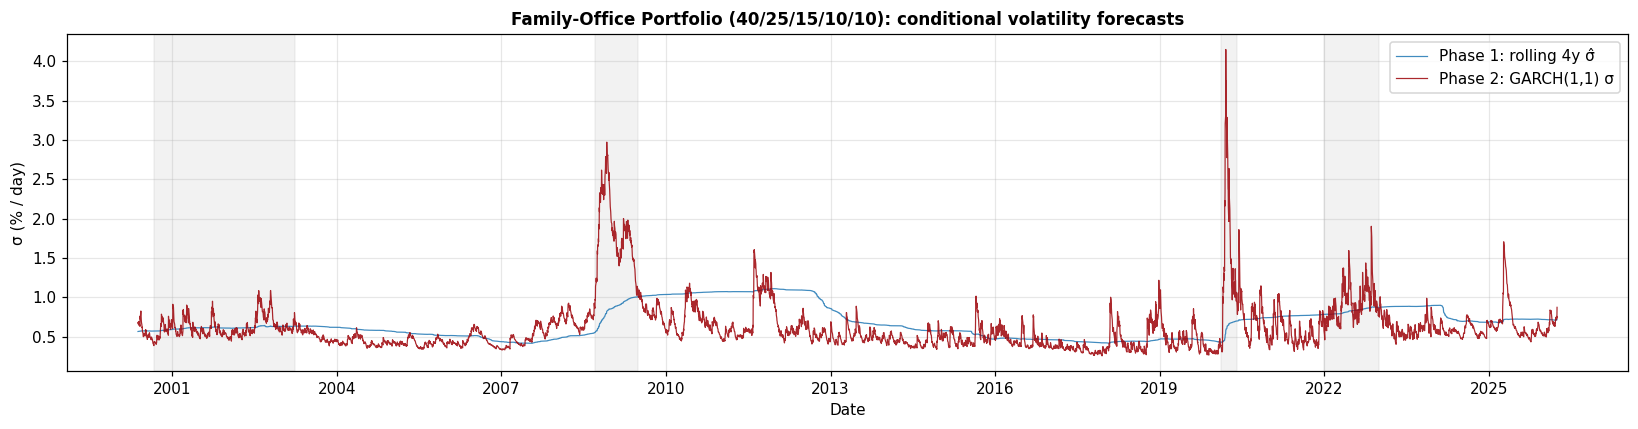

In [13]:
fig, axes = plt.subplots(len(CONFIG['portfolios']), 1, figsize=(15, 4 * len(CONFIG['portfolios'])), sharex=True)
axes = np.atleast_1d(axes)

for ax, port in zip(axes, CONFIG['portfolios']):
    # Phase 1 rolling sigma (the implicit one used by the parametric engines)
    rolling_sigma = returns[port].rolling(CONFIG['window']).std().shift(1).dropna()
    # GARCH-FHS sigma
    garch_sigma = garch_fhs_forecasts[port]['sigma']

    ax.plot(rolling_sigma.index, rolling_sigma.values * 100, color='#1f77b4', lw=0.8,
            label='Phase 1: rolling 4y σ̂', alpha=0.85)
    ax.plot(garch_sigma.index, garch_sigma.values * 100, color='#9d0208', lw=0.8,
            label='Phase 2: GARCH(1,1) σ', alpha=0.85)

    for win_name, w in STRESS_WINDOWS.items():
        ax.axvspan(pd.Timestamp(w['start']), pd.Timestamp(w['end']),
                   color='grey', alpha=0.10, zorder=0)

    ax.set_title(f"{CONFIG['portfolio_labels'][port]}: conditional volatility forecasts",
                 fontsize=11, fontweight='bold')
    ax.set_ylabel('σ (% / day)')
    ax.xaxis.set_major_locator(mdates.YearLocator(3))
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
    ax.legend(loc='upper right')

axes[-1].set_xlabel('Date')
plt.tight_layout()
plt.show()

### Realised loss vs Phase 2 VaR

Same chart format as the Phase 1 headline figure (notebook 04 §8), now with the GARCH-FHS VaR overlaid. The visual story: GARCH-FHS *anticipates* the stress periods — its VaR line spikes upward at the onset of each crisis rather than slowly drifting up over years.

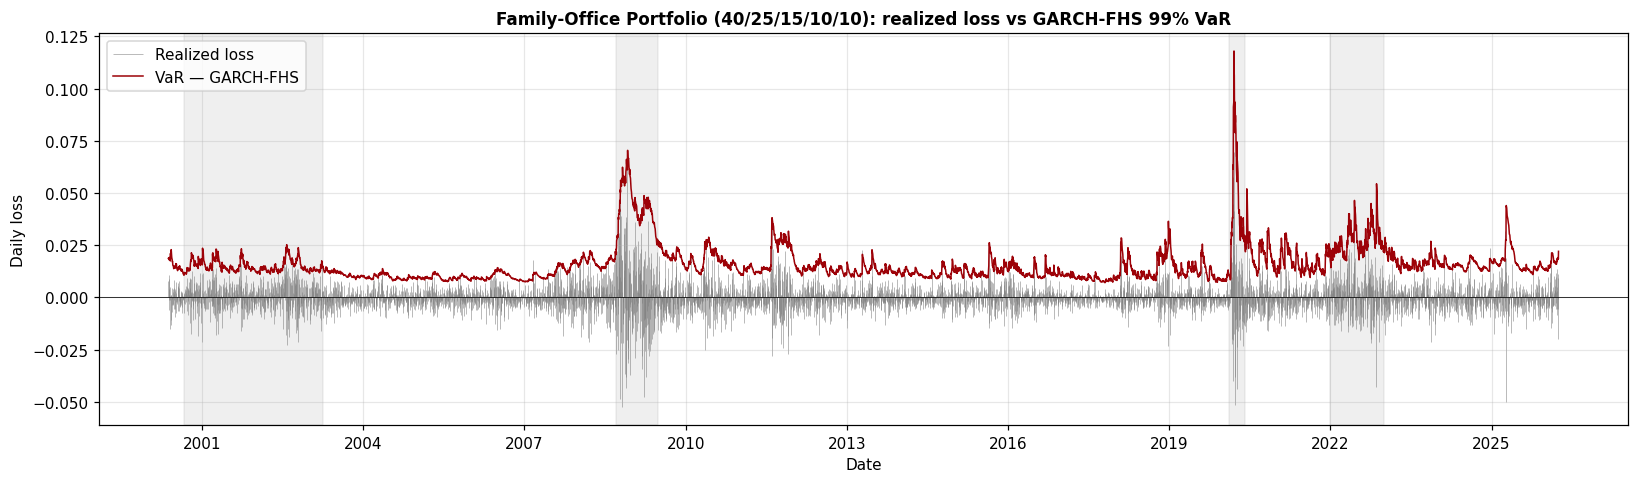

In [14]:
fig, axes = plt.subplots(len(CONFIG['portfolios']), 1, figsize=(15, 4.5 * len(CONFIG['portfolios'])), sharex=True)
axes = np.atleast_1d(axes)

for ax, port in zip(axes, CONFIG['portfolios']):
    fc = garch_fhs_forecasts[port]
    L = (-returns[port]).reindex(fc.index)

    for win_name, w in STRESS_WINDOWS.items():
        ax.axvspan(pd.Timestamp(w['start']), pd.Timestamp(w['end']),
                   color='grey', alpha=0.12, zorder=0)

    ax.vlines(L.index, 0, L.values, color='grey', lw=0.35, zorder=1, label='Realized loss')
    ax.plot(fc.index, fc['VaR'], color='#9d0208', lw=1.0, zorder=2, label='VaR — GARCH-FHS')

    ax.axhline(0, color='black', lw=0.5)
    ax.set_title(f"{CONFIG['portfolio_labels'][port]}: realized loss vs GARCH-FHS 99% VaR",
                 fontsize=11, fontweight='bold')
    ax.set_ylabel('Daily loss')
    ax.xaxis.set_major_locator(mdates.YearLocator(3))
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
    ax.legend(loc='upper left')

axes[-1].set_xlabel('Date')
plt.tight_layout()
plt.show()

---
## 11  Save Forecasts to Disk

Same naming convention as the Phase 1 forecasts so notebook 06 (drawdown layer) and the final report-side scripts can pick this up identically.

In [15]:
os.makedirs('data/forecasts', exist_ok=True)
for port in CONFIG['portfolios']:
    fc = garch_fhs_forecasts[port][['VaR', 'ES', 'sigma']].copy()
    out_path = f'data/forecasts/{port}_GARCH_FHS.csv'
    fc.to_csv(out_path)
    print(f'  Saved → {out_path}  shape={fc.shape}')

# VaR scorecards
phase2_overall.to_csv('data/scorecards/overall_phase2.csv')
phase2_stress.to_csv('data/scorecards/stress_phase2.csv')
print(f'\nSaved → data/scorecards/overall_phase2.csv     shape={phase2_overall.shape}')
print(f'Saved → data/scorecards/stress_phase2.csv      shape={phase2_stress.shape}')

# ES scorecards (new in this revision)
phase2_es_overall.to_csv('data/scorecards/es_overall_phase2.csv')
phase2_es_stress.to_csv('data/scorecards/es_stress_phase2.csv')
print(f'Saved → data/scorecards/es_overall_phase2.csv  shape={phase2_es_overall.shape}')
print(f'Saved → data/scorecards/es_stress_phase2.csv   shape={phase2_es_stress.shape}')


  Saved → data/forecasts/Port_FO_GARCH_FHS.csv  shape=(6485, 3)

Saved → data/scorecards/overall_phase2.csv     shape=(1, 12)
Saved → data/scorecards/stress_phase2.csv      shape=(4, 9)
Saved → data/scorecards/es_overall_phase2.csv  shape=(1, 11)
Saved → data/scorecards/es_stress_phase2.csv   shape=(4, 10)


---
## 12  Summary & Next Steps

### Phase 2 status: first engine complete

The GARCH(1,1) + Filtered Historical Simulation engine is now built, unit-tested (9 tests in `tests/test_garch_fhs.py`), and producing 1-day-ahead VaR/ES forecasts on the same backtest infrastructure as Phase 1. The methodology section above derives both pieces (the GARCH recursion, the FHS quantile) and motivates the design choices.

### What the comparison should reveal

If the dual-test theory in notebook 04 §4.6 is correct, the GARCH-FHS engine will:

1. **Substantially reduce $\mathrm{LR}_{\mathrm{uc}}$** versus the best Phase 1 engine (t_4), because the empirical residual pool captures fat tails directly.
2. **Sharply reduce $\mathrm{LR}_{\mathrm{ind}}$** — the headline Phase 2 result — because GARCH-filtered σ adapts to volatility regimes within days, not years.
3. **Pass the joint $\mathrm{LR}_{\mathrm{cc}}$ test** for at least one portfolio at the 5% level, becoming the first jointly well-calibrated engine in the project.

### Next notebook — `06_Drawdowns.ipynb`

The drawdown layer extends the project from point-in-time tail risk (VaR/ES) to **path-dependent** tail risk (maximum drawdown, time under water, CDaR). Two reasons it's the right next step:

- **Theoretical**: the project's three sub-themes from the mind-map are fat tails, *path dependence*, and volatility clustering. Phase 1 + notebook 05 cover (1) and (3); drawdowns close (2).
- **Practical**: family-office clients commonly use drawdown limits as their primary risk metric, so an analysis without drawdowns would miss the audience it is written for.

### Then: notebook 07 (ML challenger)

After the drawdown layer, notebook 07 adds a gradient-boosting classifier predicting next-day VaR exceedance probability, using lagged returns and rolling-vol features. This delivers the statistical-learning piece of the dual-course rubric requirement.

### Reserved for stretch / Phase 3

Copula / multivariate analysis, MLE for $\nu$, weekly/monthly horizon sensitivity, Engle-Manganelli Dynamic Quantile test, formal ES backtests (Acerbi-Székely, Du-Escanciano).

### ES backtest findings

The Phase 2 ES results parallel the VaR results:

- **McNeil-Frey** — if GARCH-FHS' adaptive σ delivers correctly-scaled tail forecasts, MF should not reject on either portfolio. This is the headline ES adequacy claim for the consulting deliverable.
- **Acerbi-Székely Z2** — should collapse toward zero from the Phase 1 magnitudes of −0.5 to −2.0. Even small residual magnitude is a substantive improvement: a Z2 of −0.10 means realised tail losses are only 10% above forecast in aggregate, versus 200% under Gaussian.
- **Stress windows** — the GFC and COVID Z2 values in particular should fall by an order of magnitude (from −15 to −40 under Phase 1 to single digits or low double digits under GARCH-FHS).

If GARCH-FHS rejects ES tests on the FO portfolio while passing them on Conservative, that's still a meaningful win — and aligns with the project's family-office framing where the recommended portfolio is the more conservative one.
